## Benutils vs. PyTorch

### Question 
The purpose of this investigation is to understand and compare specific differences between my scratch network training engine, benutils, and the common open-source ML framework, PyTorch, under controlled conditions.

### Methodology
This investigation will be centered around training 2 neural network models on [Boston Housing](https://www.kaggle.com/code/prasadperera/the-boston-housing-dataset), a legacy testing dataset.

[The imported  dataset](https://www.kaggle.com/datasets/vikrishnan/boston-house-prices/data), is readily available to our models within this folder. It serves as a benchmark for model performance comparisons. I chose this established testing because of a history of consistent rigourous testing, evaluations, and familiarity that will help isolate variables for comparisons. 

For running and displaying output from benutils, the vanilla JavaScript library, I will utilize a Python subprocess and node.js.

##### Architecture
This investigation will compare performances for all 3 of benutils' basic architecture types: po2, power of two, and hourglass. Hourglass architecture will be using it's default operator, "/", leading to the standard contract-to-center into expanion-to-end shape that is associated with the hourglass name. 

However, before getting into full tests, I will create an extremely simple 2->2->1 model and manually match the weights of both to test basic functionality and math implementation.

In [ ]:
%%script node

import {neuralnet, set_features} from "../src/network.js";

const model = neuralnet({
    hidden_layer_info: {
        count:1, 
        init_size:2, 
        style:"po2"
    },
    activation_type:"relu",
    learn_rate:.01,
    output_layer_info:{
        init_size:1, 
        activation:"none"
    },
    epochs:1,
    tt_split:0,
    random_seed:33463,
    batch_size:1
});

const features_in = {
    "feat1":[3.0, 12.0, 25.0],
    "feat2":[5.0, 15.0, 35.0],
    "TARGET":[22.0, 40.0, 11.0]
}

//Set features, but dont shuffle the values
model.set_features(features_in, false);

model.train();

console.log("\n\n BENUTILS POST TRAINING UPDATED WEIGHTS:")

/* "A SECOND COPY OF THIS LOGGIN PROCEDURE WAS TEMPORARILY PLACED IN model.train() to log initial weight and bias values."
    "Thankfully, due to seeding, it stays consistent. Initial output is saved as the first output of this cell"*/
console.log("--input_layer--","\nvalues:", model.layers["input_layer"]["output"]);
console.log();
console.log("--hidden_layer_1--", "weights:", model.layers["hidden_layer_1"]["main"]["weights"], "\nbiases:", model.layers["hidden_layer_1"]["main"]["biases"], "\nvalues:", model.layers["hidden_layer_1"]["output"]);
console.log();
console.log("--output_layer--", "\nweights:", model.layers["output_layer"]["main"]["weights"], "\nbiases:", model.layers["output_layer"]["main"]["biases"], "\nvalues:", model.layers["output_layer"]["output"]);



now buidling model[SEED: 33463]
1 epochs
0 train/test split
relu activation
1 batch size
flat architecture, hg_oper?: /
0.01 learning rate
--input_layer-- 
values: []

--hidden_layer_1-- weights: [
  [ 0.5110150227328565, 1.2756492915094295 ],
  [ -0.5771150797856148, 0.6096600024628742 ]
] 
biases: [ 0, 0 ] 
values: []

--output_layer-- 
weights: [ [ 1.292116896082979, -0.41084944789670486 ] ] 
biases: [ 0 ] 
values: []


 BENUTILS POST TRAINING UPDATED WEIGHTS:
--input_layer-- 
values: [ 25, 35 ]

--hidden_layer_1-- weights: [
  [ -14.734454171092503, -17.582221280030623 ],
  [ -0.7289497113452345, 0.35660228319684145 ]
] 
biases: [ -1.1510762137071242, -0.05061154385320655 ] 
values: [ 0, 0 ]

--output_layer-- 
weights: [ [ -22.643741723699275, -0.2486169936839701 ] ] 
biases: [ -0.3403090035059921 ] 
values: [ -0.4548575792989819 ]


Matching that parameter initialization in PyTorch:

In [55]:
import torch
from torch.utils.data import Dataset, DataLoader


import numpy as np
import pandas as pd

import json

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


class Network(torch.nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.input_layer = torch.nn.Linear(in_features=input_dim, out_features=2)
        self.hidden_layer = torch.nn.Linear(2, 1)

    def forward(self, x):
        x = torch.relu(self.input_layer(x))
        x = self.hidden_layer(x)
        return x

#MANUALLY MATCHING PARAMETER VALUES TO BENUTILS RUN
simple_input = torch.tensor([[3.0, 5.0], [12.0, 15.0], [25.0, 35.0]])
simple_targets = torch.tensor([[22.0], [40.0], [11.0]])

# 2 feature input layer
model = Network(input_dim=2)

custom_input_weights = torch.tensor(
    [[ 0.5110150227328565, 1.2756492915094295 ],
    [-0.5771150797856148, 0.6096600024628742]]
)

custom_output_weights = torch.tensor(
    [[ 1.292116896082979, -0.41084944789670486 ]]
)

with torch.no_grad():
    model.input_layer.weight.copy_(custom_input_weights)
    model.input_layer.bias.fill_(0)

    model.hidden_layer.weight.copy_(custom_output_weights)
    model.hidden_layer.bias.fill_(0)

weights_dict = model.state_dict()

for key in weights_dict.keys():
    print(key, weights_dict[key])

input_layer.weight tensor([[ 0.5110,  1.2756],
        [-0.5771,  0.6097]])
input_layer.bias tensor([0., 0.])
hidden_layer.weight tensor([[ 1.2921, -0.4108]])
hidden_layer.bias tensor([0.])


Now that our initial parameters are matching, we must a design difference that makes running a seemingly equivalent PyTorch training procedure yield different results.

PyTorch's mean squared error loss equation uses the pure mathmatical definition of MSE, without the 1/2 scaler that is commonly used to simplify the process of calculating loss. In practice, this only affects the scale of the delta values, which means we can easily account for it without ruining either implementation.

Lets see the parameters after training through 1 epoch of our simple example data, accounting for PyTorch's gradient equation by multiplying it's loss calculations by 0.5:

In [56]:
criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Loop to mimic benutils batch_size: 1 behavior
for i in range(len(simple_input)):
    optimizer.zero_grad()
    
    # Take one sample at a time with a batch of 1
    single_input = simple_input[i].unsqueeze(0)
    single_target = simple_targets[i].unsqueeze(0)
    
    predictions = model(single_input)
    loss = 0.5 * criterion(predictions, single_target) # Accounting for pure MSE calculation
    
    loss.backward()
    optimizer.step()

print("PYTORCH POST-TRAINING UPDATED WEIGHTS:")

weights_dict = model.state_dict()
for key in weights_dict.keys():
    print("\n", key, weights_dict[key])

print("\noutput: ", predictions[0])

PYTORCH POST-TRAINING UPDATED WEIGHTS:

 input_layer.weight tensor([[-14.7345, -17.5822],
        [ -0.7289,   0.3566]])

 input_layer.bias tensor([-1.1511, -0.0506])

 hidden_layer.weight tensor([[-22.6437,  -0.2486]])

 hidden_layer.bias tensor([-0.3403])

output:  tensor([-0.4549], grad_fn=<SelectBackward0>)


##### We can now see that the parameter values between the models are matching! This confirms that benutils' training procedures, at least within this test-case, are implemented correctly and allows us to move on to comparing their behavior involving larger architecture.
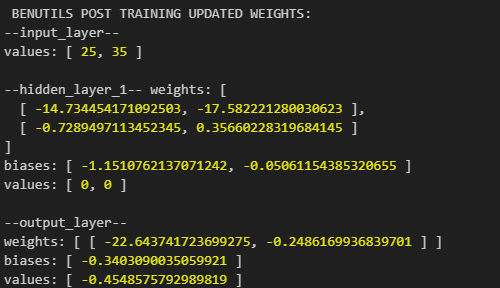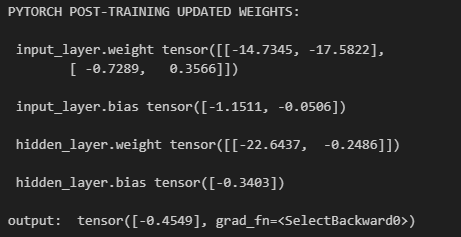

## Phase 2: Full Architecture Performance Comparison

##### First, we will compare the models on the benutils **flat** architecture:

Since our unit-test was successful, we no longer need to match parameter initializations 1:1 between the models. Since this experiment is meant to highlight the differences between the engine implementation, it seems most reasonable to compare them with their native implementations of generation and training. This change will include removing the forced loss scaler from phase 1, as it is no longer needed.

For the flat architecture test, we'll try a single hidden layer with 32 neurons, and ReLU activation for 50 epochs.

But first, we will shuffle the dataset, split it data into train/test sets, normalize it, and export it as a csv for PyTorch and a JS object for benutils to gaurentee exactly the same preprocessing without relying on either frameworks' native solutions:

In [57]:
df = pd.read_csv('./housing.csv', header=None)

#Drop target column MEDV
X = df.drop(df.columns[-1], axis=1)

#Set target to just MEDV
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, random_state=489)

numeric_cols = X_train.select_dtypes(include=['number']).columns

scaler = MinMaxScaler()

X_train_norm = X_train.copy()
X_train_norm[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

X_test_norm = X_test.copy()
X_test_norm[numeric_cols] = scaler.transform(X_test[numeric_cols])

train_full = X_train_norm.copy()
train_full['target'] = y_train
train_full.to_csv('train_normalized.csv', index=False)

test_full = X_test_norm.copy()
test_full['target'] = y_test
test_full.to_csv('test_normalized.csv', index=False)

Because benutils' metric reporting is almost entirely based on it's own normalization function saving feature min/max values, we will have to export it's raw predictions and calculate the metrics via Python.

Moving on to benutils flat architecture test:

In [58]:
%%script node

import {neuralnet, set_features_csv, normalize_features} from "../src/network.js";
import {trainNormRaw} from "./train_normalized.js";
import {testNormRaw} from "./test_normalized.js";
import fs from 'fs';

const feature_selection = {
    "TARGET":13,
    //put features below
    "CRIM":0,
    "ZN":1,
    "INDUS":2,
    "CHAS":3,
    "NOX":4,
    "RM":5,
    "AGE":6,
    "DIS":7,
    "RAD":8,
    "TAX":9,
    "PTRATIO":10,
    "B":11,
    "LSTAT":12
}

const model = neuralnet({
    hidden_layer_info: {
        count:1, 
        init_size:32, 
        style:"flat"
    },
    activation_type:"relu",
    learn_rate:.01,
    output_layer_info:{
        init_size:1, 
        activation:"none"
    },
    epochs:100,
    tt_split:0,
    random_seed:33463,
    batch_size:10
});

model.set_features_csv(trainNormRaw, feature_selection, false);


model.train();

const trainingPredictions = model.properties.predictions_and_targets.training.raw_predictions;

//writing to JSON file to be able to interpret
fs.writeFileSync('training_predictions.json', JSON.stringify(trainingPredictions));


//Importing test data into benutils data
const temp_model = neuralnet({tt_split: 1});

temp_model.set_features_csv(testNormRaw, feature_selection, false)
temp_model.train();

const testingSet = temp_model.properties.stored_testing_data.t_feature_data;

//Using a random feature because benutils test() uses target length to identify number of observations
const setCopy = {...testingSet}
setCopy["TARGET"] = setCopy["RM"]

model.properties.stored_testing_data.t_target_data = setCopy;

//Placing the test data into the models testing data properties
model.properties.stored_testing_data.t_feature_data = testingSet;

model.test();

const testingPredictions = model.properties.predictions_and_targets.testing.raw_predictions
fs.writeFileSync('testing_predictions.json', JSON.stringify(testingPredictions));




now buidling model[SEED: 33463]
100 epochs
0 train/test split
relu activation
10 batch size
flat architecture, hg_oper?: /
0.01 learning rate
now buidling model[SEED: 58373]
100 epochs
1 train/test split
relu activation
10 batch size
flat architecture, hg_oper?: /
0.01 learning rate


Interpreting benutils metrics in python:

In [59]:
with open('./training_predictions.json', 'r') as f:
    train_y_pred = json.load(f)

train_y_pred = np.array(train_y_pred).flatten()

mse = mean_squared_error(y_train, train_y_pred)
mae = mean_absolute_error(y_train, train_y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, train_y_pred)

with open('./testing_predictions.json', 'r') as f:
    test_y_pred = json.load(f)

t_mse = mean_squared_error(y_test, test_y_pred)
t_mae = mean_absolute_error(y_test, test_y_pred)
t_rmse = np.sqrt(t_mse)
t_r2 = r2_score(y_test, test_y_pred)

print("BENUTILS TRAINING SET METRICS (FINAL EPOCH):")
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")

print("\nBENUTILS TESTING SET METRICS:")
print(f"MSE: {t_mse}")
print(f"MAE: {t_mae}")
print(f"RMSE: {t_rmse}")
print(f"R2: {t_r2}")


BENUTILS TRAINING SET METRICS (FINAL EPOCH):
MSE: 10.320144428489094
MAE: 2.303048170801742
RMSE: 3.212498160075597
R2: 0.8825373834692276

BENUTILS TESTING SET METRICS:
MSE: 13.980210971670529
MAE: 2.4298033435491075
RMSE: 3.739012031495824
R2: 0.8114048639829485


Our results indicate that benutils successfully learned a pattern from the dataset using a single 32 neuron hidden layer and ReLU activation. The overfitting descrepency between training and testing metrics is understandable considering the ratio of neurons to parameters. 

Let's see how PyTorch performs in the same controlled conditions.


In [60]:
torch.manual_seed(42)

df = pd.read_csv('train_normalized.csv')

flat_training_X = df.drop(columns=['target'])
flat_training_X = flat_training_X.values

flat_training_y = df['target'].values

class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

flat_train_dataset = TabularDataset(flat_training_X, flat_training_y)

flat_train_loader = DataLoader(flat_train_dataset, batch_size=10, shuffle=False)

class FlatNetwork(torch.nn.Module):
    def __init__(self, input_dim):
        super(FlatNetwork, self).__init__()

        self.network = torch.nn.Sequential(
            torch.nn.Linear(input_dim, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

flat_model = FlatNetwork(input_dim=13)

optimizer = torch.optim.Adam(flat_model.parameters(), lr=0.01)

epochs = 100

for e in range(epochs):
    flat_model.train()
    running_loss = 0.0

    for batch_X, batch_y in flat_train_loader:

        predictions = flat_model(batch_X)
        loss = criterion(predictions, batch_y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

    epoch_loss = running_loss/len(flat_train_loader.dataset)
    if (e + 1) % 10 == 0 or e == 0:
        print(f"Epoch {e+1}/{epochs} - Loss: {epoch_loss}")

flat_model.eval()
with torch.no_grad():
    y_pred_torch = flat_model(torch.tensor(flat_training_X, dtype=torch.float32)).numpy().flatten()

pt_mse = mean_squared_error(flat_training_y, y_pred_torch)
pt_mae = mean_absolute_error(flat_training_y, y_pred_torch)
pt_rmse = np.sqrt(pt_mse)
pt_r2 = r2_score(flat_training_y, y_pred_torch)

print("\n--- PYTORCH FINAL TRAINING METRICS ---")
print(f"MSE: {pt_mse}")
print(f"MAE: {pt_mae}")
print(f"RMSE: {pt_rmse}")
print(f"R²:  {pt_r2}")    

Epoch 1/100 - Loss: 405.35569199534393
Epoch 10/100 - Loss: 29.975491631943193
Epoch 20/100 - Loss: 20.280639374161773
Epoch 30/100 - Loss: 17.904357913930685
Epoch 40/100 - Loss: 16.194911486240677
Epoch 50/100 - Loss: 15.11368552235626
Epoch 60/100 - Loss: 14.220624089555564
Epoch 70/100 - Loss: 13.51342033899554
Epoch 80/100 - Loss: 12.856870741831596
Epoch 90/100 - Loss: 12.266259695420478
Epoch 100/100 - Loss: 11.625604658453948

--- PYTORCH FINAL TRAINING METRICS ---
MSE: 10.874150828836875
MAE: 2.293595081520584
RMSE: 3.297597736055275
R²:  0.8762317506546322


In [61]:
df = pd.read_csv('test_normalized.csv')

flat_testing_X = df.drop(columns=['target'])
flat_testing_X = flat_testing_X.values

flat_testing_y = df['target'].values

flat_test_dataset = TabularDataset(flat_testing_X, flat_testing_y)

flat_test_loader = DataLoader(flat_test_dataset, batch_size=10, shuffle=False)

flat_model.eval()
test_preds = []
test_actuals = []
test_running_loss = 0.0

for batch_X, batch_y in flat_test_loader:
    predictions = flat_model(batch_X)
    loss = criterion(predictions, batch_y)

    test_running_loss += loss.item() * batch_X.size(0)
    
test_epoch_loss = test_running_loss/len(flat_test_loader.dataset)

with torch.no_grad():
    y_pred_torch = flat_model(torch.tensor(flat_testing_X, dtype=torch.float32)).numpy().flatten()


t_pt_mse = mean_squared_error(flat_testing_y, y_pred_torch)
t_pt_mae = mean_absolute_error(flat_testing_y, y_pred_torch)
t_pt_rmse = np.sqrt(t_pt_mse)
t_pt_r2 = r2_score(flat_testing_y, y_pred_torch)


print("\n--- PYTORCH FINAL TESTING METRICS ---")
print(f"Test loss: {test_epoch_loss}")
print(f"MSE: {t_pt_mse}")
print(f"MAE: {t_pt_mae}")
print(f"RMSE: {t_pt_rmse}")
print(f"R²:  {t_pt_r2}")


--- PYTORCH FINAL TESTING METRICS ---
Test loss: 17.082823340348373
MSE: 17.082821472390354
MAE: 2.3470611692413583
RMSE: 4.133137001405876
R²:  0.7695501844951419


**Visual representation of both flat architecture models we created, using VFL-NN-MODEL-STUDIO (Simply for visualizing shape, values are not accurate):**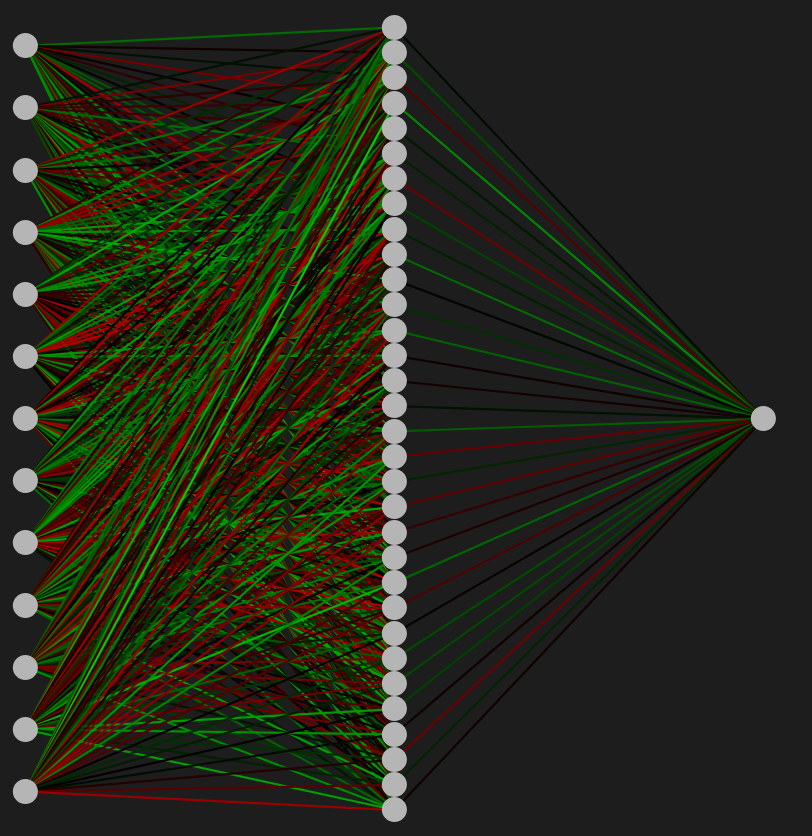

Both models' performances show gradients moving in the right direction and a tendency to overfit with this setup. It seemed initially very odd that PyTorch's Adam optimized network seems to do worse overall than the benutils run on this architecture. However, it must be understood that it is not unusual for PyTorch's Adam optimizer to perform differently than Stochastic Gradient Descent (SGD) on relatively small tabular datasets. As with many things, there comes a point where the added optimizations overcomplicate an extremely simple problem space. benutils, having been built with exclusively fundamental implementations of neural network procedure and SGD optimization, performs competitively in this test due to what may ultimately be algorithmic simplicity.

##### Comparison of the models on benutils' **Power of Two (po2)** architecture type.

_2 hidden layers, in(13) -> 16 -> 8 -> out(1), all other model settings held constant_

benutils:

In [62]:
%%script node

import {neuralnet, set_features_csv, normalize_features} from "../src/network.js";
import {trainNormRaw} from "./train_normalized.js";
import {testNormRaw} from "./test_normalized.js";
import fs from 'fs';

const feature_selection = {
    "TARGET":13,
    //put features below
    "CRIM":0,
    "ZN":1,
    "INDUS":2,
    "CHAS":3,
    "NOX":4,
    "RM":5,
    "AGE":6,
    "DIS":7,
    "RAD":8,
    "TAX":9,
    "PTRATIO":10,
    "B":11,
    "LSTAT":12
}

const model = neuralnet({
    hidden_layer_info: {
        count:2, 
        init_size:16, 
        style:"po2" // CHANGED ARCHITECTURE
    },
    activation_type:"relu",
    learn_rate:.01,
    output_layer_info:{
        init_size:1, 
        activation:"none"
    },
    epochs:100,
    tt_split:0,
    random_seed:33463,
    batch_size:10
});

model.set_features_csv(trainNormRaw, feature_selection, false);


model.train();

const trainingPredictions = model.properties.predictions_and_targets.training.raw_predictions;

//writing to JSON file to be able to interpret
fs.writeFileSync('po2_training_predictions.json', JSON.stringify(trainingPredictions));


//Importing test data into benutils data
const temp_model = neuralnet({tt_split: 1});

temp_model.set_features_csv(testNormRaw, feature_selection, false)
temp_model.train();

const testingSet = temp_model.properties.stored_testing_data.t_feature_data;

//Using a random feature because benutils test() uses target length to identify number of observations
const setCopy = {...testingSet}
setCopy["TARGET"] = setCopy["RM"]

model.properties.stored_testing_data.t_target_data = setCopy;

//Placing the test data into the models testing data properties
model.properties.stored_testing_data.t_feature_data = testingSet;

model.test();

const testingPredictions = model.properties.predictions_and_targets.testing.raw_predictions
fs.writeFileSync('po2_testing_predictions.json', JSON.stringify(testingPredictions));




now buidling model[SEED: 33463]
100 epochs
0 train/test split
relu activation
10 batch size
po2 architecture, hg_oper?: /
0.01 learning rate


now buidling model[SEED: 58373]
100 epochs
1 train/test split
relu activation
10 batch size
flat architecture, hg_oper?: /
0.01 learning rate


Python imported metric reporting:

In [63]:
with open('./po2_training_predictions.json', 'r') as f:
    train_y_pred = json.load(f)

train_y_pred = np.array(train_y_pred).flatten()

mse = mean_squared_error(y_train, train_y_pred)
mae = mean_absolute_error(y_train, train_y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, train_y_pred)

with open('./po2_testing_predictions.json', 'r') as f:
    test_y_pred = json.load(f)

t_mse = mean_squared_error(y_test, test_y_pred)
t_mae = mean_absolute_error(y_test, test_y_pred)
t_rmse = np.sqrt(t_mse)
t_r2 = r2_score(y_test, test_y_pred)

print("BENUTILS TRAINING SET METRICS (FINAL EPOCH):")
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")

print("\nBENUTILS TESTING SET METRICS:")
print(f"MSE: {t_mse}")
print(f"MAE: {t_mae}")
print(f"RMSE: {t_rmse}")
print(f"R2: {t_r2}")

BENUTILS TRAINING SET METRICS (FINAL EPOCH):
MSE: 8.43756933130969
MAE: 2.0815625425888022
RMSE: 2.9047494438091714
R2: 0.9039646220377038

BENUTILS TESTING SET METRICS:
MSE: 12.54554240926126
MAE: 2.3542593818868873
RMSE: 3.5419687194075076
R2: 0.8307587573694826


Solid metrics from benutils, PyTorch with everything except architecture remaining constant:

In [64]:
torch.manual_seed(42)

df = pd.read_csv('train_normalized.csv')

po2_training_X = df.drop(columns=['target'])
po2_training_X = po2_training_X.values

po2_training_y = df['target'].values

class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

po2_train_dataset = TabularDataset(po2_training_X, po2_training_y)

po2_train_loader = DataLoader(po2_train_dataset, batch_size=10, shuffle=False)

class Po2Network(torch.nn.Module):
    def __init__(self, input_dim):
        super(Po2Network, self).__init__()

        self.network = torch.nn.Sequential(
            torch.nn.Linear(input_dim, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 8),
            torch.nn.ReLU(),
            torch.nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

po2_model = Po2Network(input_dim=13)

optimizer = torch.optim.Adam(po2_model.parameters(), lr=0.01)

epochs = 100

for e in range(epochs):
    po2_model.train()
    running_loss = 0.0

    for batch_X, batch_y in po2_train_loader:

        predictions = po2_model(batch_X)
        loss = criterion(predictions, batch_y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

    epoch_loss = running_loss/len(po2_train_loader.dataset)
    if (e + 1) % 10 == 0 or e == 0:
        print(f"Epoch {e+1}/{epochs} - Loss: {epoch_loss}")

po2_model.eval()
with torch.no_grad():
    y_pred_torch = po2_model(torch.tensor(po2_training_X, dtype=torch.float32)).numpy().flatten()

pt_mse = mean_squared_error(po2_training_y, y_pred_torch)
pt_mae = mean_absolute_error(po2_training_y, y_pred_torch)
pt_rmse = np.sqrt(pt_mse)
pt_r2 = r2_score(po2_training_y, y_pred_torch)

print("\n--- PYTORCH FINAL TRAINING METRICS ---")
print(f"MSE: {pt_mse}")
print(f"MAE: {pt_mae}")
print(f"RMSE: {pt_rmse}")
print(f"R²:  {pt_r2}")    

Epoch 1/100 - Loss: 484.0378007310047
Epoch 10/100 - Loss: 26.66253739359511
Epoch 20/100 - Loss: 18.741690248172326
Epoch 30/100 - Loss: 16.440774538900733
Epoch 40/100 - Loss: 14.9789652220492
Epoch 50/100 - Loss: 13.964485226331727
Epoch 60/100 - Loss: 13.587499569462597
Epoch 70/100 - Loss: 12.609877913482585
Epoch 80/100 - Loss: 11.613806214999398
Epoch 90/100 - Loss: 10.809705566919574
Epoch 100/100 - Loss: 10.454809307108453

--- PYTORCH FINAL TRAINING METRICS ---
MSE: 10.290224857221537
MAE: 2.2459419056733867
RMSE: 3.2078380347551114
R²:  0.8828779243551541


In [65]:
df = pd.read_csv('test_normalized.csv')

po2_testing_X = df.drop(columns=['target'])
po2_testing_X = po2_testing_X.values

po2_testing_y = df['target'].values

po2_test_dataset = TabularDataset(po2_testing_X, po2_testing_y)

po2_test_loader = DataLoader(po2_test_dataset, batch_size=10, shuffle=False)

po2_model.eval()
test_preds = []
test_actuals = []
test_running_loss = 0.0

for batch_X, batch_y in po2_test_loader:
    predictions = po2_model(batch_X)
    loss = criterion(predictions, batch_y)

    test_running_loss += loss.item() * batch_X.size(0)
    
test_epoch_loss = test_running_loss/len(po2_test_loader.dataset)

with torch.no_grad():
    y_pred_torch = po2_model(torch.tensor(po2_testing_X, dtype=torch.float32)).numpy().flatten()


t_pt_mse = mean_squared_error(po2_testing_y, y_pred_torch)
t_pt_mae = mean_absolute_error(po2_testing_y, y_pred_torch)
t_pt_rmse = np.sqrt(t_pt_mse)
t_pt_r2 = r2_score(po2_testing_y, y_pred_torch)


print("\n--- PYTORCH FINAL TESTING METRICS ---")
print(f"Test loss: {test_epoch_loss}")
print(f"MSE: {t_pt_mse}")
print(f"MAE: {t_pt_mae}")
print(f"RMSE: {t_pt_rmse}")
print(f"R²:  {t_pt_r2}")


--- PYTORCH FINAL TESTING METRICS ---
Test loss: 15.059361983471968
MSE: 15.059362096927009
MAE: 2.3259905071709106
RMSE: 3.880639392796889
R²:  0.7968469539726406


**Visual representation of both po2 architecture models we created, using VFL-NN-MODEL-STUDIO (Simply for visualizing shape, values are not accurate):**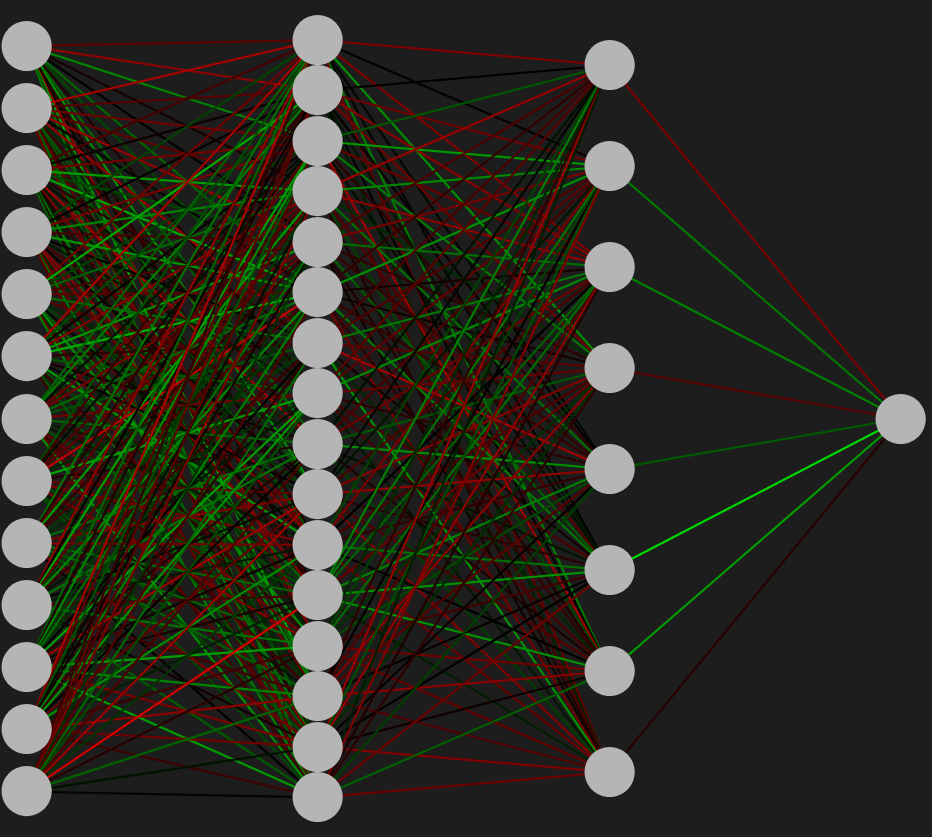

It seems that benutils' simple implementations continues to edge out PyTorch a bit on this dataset and now in this architecture type.

Lastly, we will compare benutils to PyTorch in the hourglass architecture type, creating a data bottleneck in the middle of a model with many more total parameters. </br>
in(13) -> 32 -> 16 -> 8 -> 16 -> 32 -> out(1) 

benutils:

In [85]:
%%script node

import {neuralnet, set_features_csv, normalize_features} from "../src/network.js";
import {trainNormRaw} from "./train_normalized.js";
import {testNormRaw} from "./test_normalized.js";
import fs from 'fs';

const feature_selection = {
    "TARGET":13,
    //put features below
    "CRIM":0,
    "ZN":1,
    "INDUS":2,
    "CHAS":3,
    "NOX":4,
    "RM":5,
    "AGE":6,
    "DIS":7,
    "RAD":8,
    "TAX":9,
    "PTRATIO":10,
    "B":11,
    "LSTAT":12
}

const model = neuralnet({
    hidden_layer_info: {
        count:5, 
        init_size:32, 
        style:"hourglass"
    },
    activation_type:"relu",
    learn_rate:.01,
    output_layer_info:{
        init_size:1, 
        activation:"none"
    },
    epochs:100,
    tt_split:0,
    random_seed:33463,
    batch_size:10
});

model.set_features_csv(trainNormRaw, feature_selection, false);


model.train();

const trainingPredictions = model.properties.predictions_and_targets.training.raw_predictions;

//writing to JSON file to be able to interpret
fs.writeFileSync('hour_training_predictions.json', JSON.stringify(trainingPredictions));


//Importing test data into benutils data
const temp_model = neuralnet({tt_split: 1});

temp_model.set_features_csv(testNormRaw, feature_selection, false)
temp_model.train();

const testingSet = temp_model.properties.stored_testing_data.t_feature_data;

//Using a random feature because benutils test() uses target length to identify number of observations
const setCopy = {...testingSet}
setCopy["TARGET"] = setCopy["RM"]

model.properties.stored_testing_data.t_target_data = setCopy;

//Placing the test data into the models testing data properties
model.properties.stored_testing_data.t_feature_data = testingSet;

model.test();

const testingPredictions = model.properties.predictions_and_targets.testing.raw_predictions
fs.writeFileSync('hour_testing_predictions.json', JSON.stringify(testingPredictions));




now buidling model[SEED: 33463]
100 epochs
0 train/test split
relu activation
10 batch size
hourglass architecture, hg_oper?: /
0.01 learning rate
now buidling model[SEED: 58373]
100 epochs
1 train/test split
relu activation
10 batch size
flat architecture, hg_oper?: /
0.01 learning rate


In [86]:
with open('./hour_training_predictions.json', 'r') as f:
    train_y_pred = json.load(f)

train_y_pred = np.array(train_y_pred).flatten()

mse = mean_squared_error(y_train, train_y_pred)
mae = mean_absolute_error(y_train, train_y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, train_y_pred)

with open('./hour_testing_predictions.json', 'r') as f:
    test_y_pred = json.load(f)

t_mse = mean_squared_error(y_test, test_y_pred)
t_mae = mean_absolute_error(y_test, test_y_pred)
t_rmse = np.sqrt(t_mse)
t_r2 = r2_score(y_test, test_y_pred)

print("BENUTILS TRAINING SET METRICS (FINAL EPOCH):")
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")

print("\nBENUTILS TESTING SET METRICS:")
print(f"MSE: {t_mse}")
print(f"MAE: {t_mae}")
print(f"RMSE: {t_rmse}")
print(f"R2: {t_r2}")

BENUTILS TRAINING SET METRICS (FINAL EPOCH):
MSE: 87.91683443878446
MAE: 6.772414305149281
RMSE: 9.376397732540172
R2: -0.0006586130494918851

BENUTILS TESTING SET METRICS:
MSE: 74.17074461647513
MAE: 6.319830381517496
RMSE: 8.612243878135079
R2: -0.0005744332310764211


Now, hourglass in PyTorch:

In [87]:
torch.manual_seed(42)

df = pd.read_csv('train_normalized.csv')

hour_training_X = df.drop(columns=['target'])
hour_training_X = hour_training_X.values

hour_training_y = df['target'].values

class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

hour_train_dataset = TabularDataset(hour_training_X, hour_training_y)

hour_train_loader = DataLoader(hour_train_dataset, batch_size=10, shuffle=False)

class HourNetwork(torch.nn.Module):
    def __init__(self, input_dim):
        super(HourNetwork, self).__init__()

        self.network = torch.nn.Sequential(
            torch.nn.Linear(input_dim, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 8),
            torch.nn.ReLU(),
            torch.nn.Linear(8, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

hour_model = HourNetwork(input_dim=13)

optimizer = torch.optim.Adam(hour_model.parameters(), lr=0.01)

epochs = 100

for e in range(epochs):
    hour_model.train()
    running_loss = 0.0

    for batch_X, batch_y in hour_train_loader:

        predictions = hour_model(batch_X)
        loss = criterion(predictions, batch_y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

    epoch_loss = running_loss/len(hour_train_loader.dataset)
    if (e + 1) % 10 == 0 or e == 0:
        print(f"Epoch {e+1}/{epochs} - Loss: {epoch_loss}")

hour_model.eval()
with torch.no_grad():
    y_pred_torch = hour_model(torch.tensor(hour_training_X, dtype=torch.float32)).numpy().flatten()

pt_mse = mean_squared_error(hour_training_y, y_pred_torch)
pt_mae = mean_absolute_error(hour_training_y, y_pred_torch)
pt_rmse = np.sqrt(pt_mse)
pt_r2 = r2_score(hour_training_y, y_pred_torch)

print("\n--- PYTORCH FINAL TRAINING METRICS ---")
print(f"MSE: {pt_mse}")
print(f"MAE: {pt_mae}")
print(f"RMSE: {pt_rmse}")
print(f"R²:  {pt_r2}")    

Epoch 1/100 - Loss: 402.31483781557915
Epoch 10/100 - Loss: 18.3299159752033
Epoch 20/100 - Loss: 15.895607236192848
Epoch 30/100 - Loss: 13.786245040969044
Epoch 40/100 - Loss: 11.71943920646305
Epoch 50/100 - Loss: 10.613841150555572
Epoch 60/100 - Loss: 9.289077510934392
Epoch 70/100 - Loss: 8.668164481588278
Epoch 80/100 - Loss: 8.30479999582497
Epoch 90/100 - Loss: 7.9864970845094145
Epoch 100/100 - Loss: 7.765567312139949

--- PYTORCH FINAL TRAINING METRICS ---
MSE: 7.888321150170563
MAE: 2.122941032751884
RMSE: 2.808615521955713
R²:  0.9102160973855944


In [ ]:
df = pd.read_csv('test_normalized.csv')

hour_testing_X = df.drop(columns=['target'])
hour_testing_X = hour_testing_X.values

hour_testing_y = df['target'].values

hour_test_dataset = TabularDataset(hour_testing_X, hour_testing_y)

hour_test_loader = DataLoader(hour_test_dataset, batch_size=10, shuffle=False)

hour_model.eval()
test_preds = []
test_actuals = []
test_running_loss = 0.0

for batch_X, batch_y in hour_test_loader:
    predictions = hour_model(batch_X)
    loss = criterion(predictions, batch_y)

    test_running_loss += loss.item() * batch_X.size(0)
    
test_epoch_loss = test_running_loss/len(hour_test_loader.dataset)

with torch.no_grad():
    y_pred_torch = hour_model(torch.tensor(hour_testing_X, dtype=torch.float32)).numpy().flatten()


t_pt_mse = mean_squared_error(hour_testing_y, y_pred_torch)
t_pt_mae = mean_absolute_error(hour_testing_y, y_pred_torch)
t_pt_rmse = np.sqrt(t_pt_mse)
t_pt_r2 = r2_score(hour_testing_y, y_pred_torch)


print("\n--- PYTORCH FINAL TESTING METRICS ---")
print(f"Test loss: {test_epoch_loss}")
print(f"MSE: {t_pt_mse}")
print(f"MAE: {t_pt_mae}")
print(f"RMSE: {t_pt_rmse}")
print(f"R²:  {t_pt_r2}")

22.38976377952756

--- PYTORCH FINAL TESTING METRICS ---
Test loss: 12.644278255973274
MSE: 12.644278471170871
MAE: 2.3502337252999856
RMSE: 3.555879423036005
R²:  0.8294267931335089


Clearly, something has collapsed benutils' clean record. With R^2 scores of near 0 for both training and testing sets, it seems as though the engine's simplicity caught up to it. The most likely explanation is that the increased number of layers and neurons gave the outputs a lot more opprotunities to suffer from dead ReLU issues. I have observed in the past that creating larger ReLU based models can easily cause sets to quickly compound into repeating the same prediction over and over again. Based on the values found in hour_testing_predictions,json, that is a rather safe assumption.

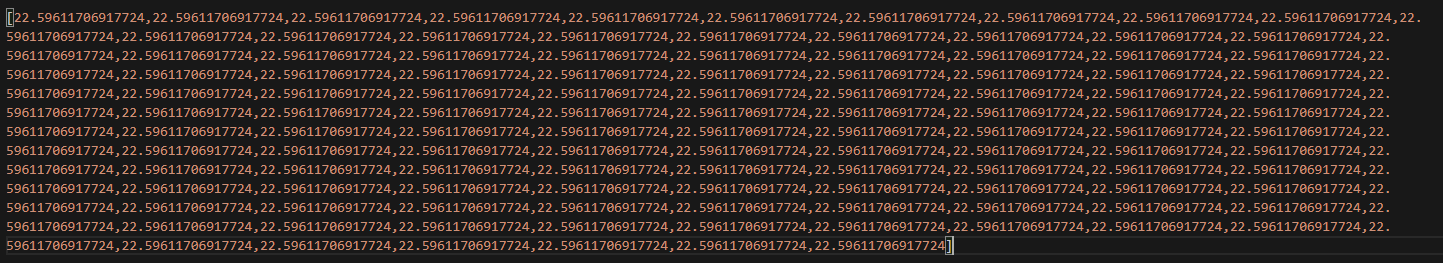

Running the model with different settings yields more standard results. In fact, in my exploration I discovered that the mean of the MEDV(target) column in the boston housing dataset we are using is:

In [95]:
print(df["target"].mean())

22.38976377952756


Considering that SGD and ReLU are notorious for falling into dead ReLU gradient valleys, the indication is only is made heavier by this discovery.

**Visual representation of both hourglass architecture models we created, using VFL-NN-MODEL-STUDIO (Simply for visualizing shape, values are not accurate):** 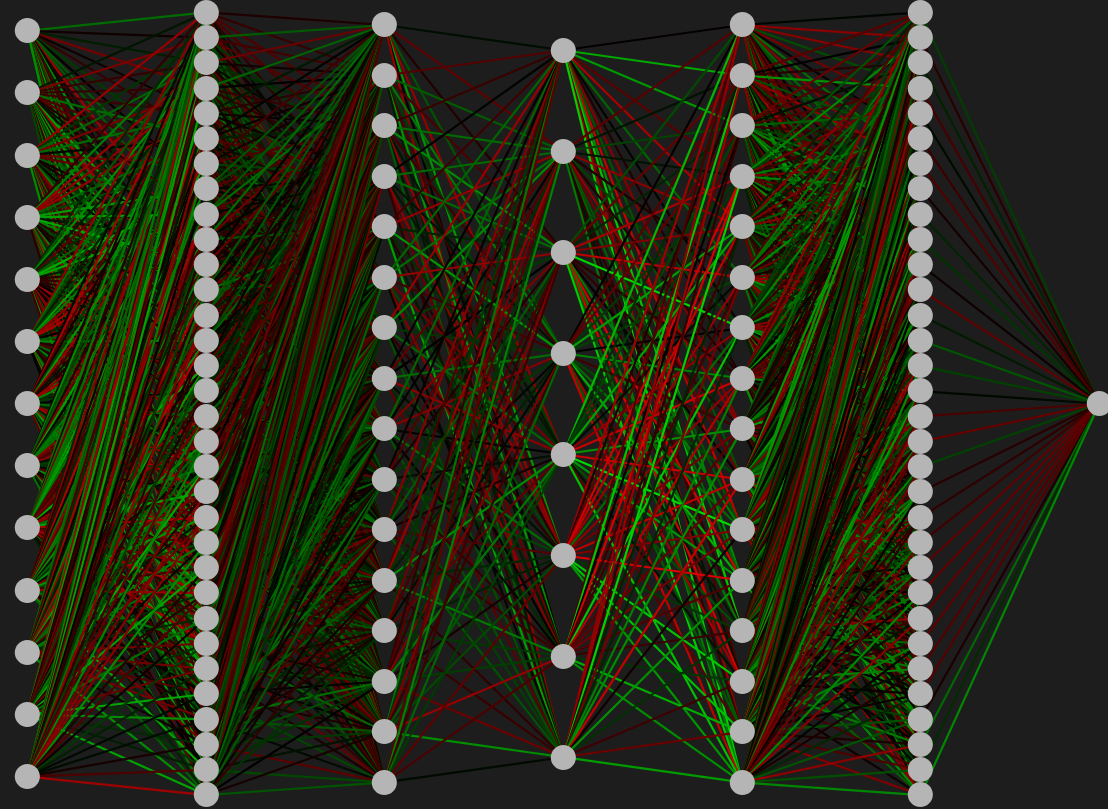